In [1]:
# load dependencies
import numpy as np
import pandas as pd
import skgstat as skg
import xarray as xr
from sklearn.preprocessing import QuantileTransformer
from skgstat import models
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.colors import LightSource
import gstatsim as gs
import random

In [2]:
# import data
ds = xr.open_dataset('BedMachineAntarctica-v3.nc')

In [18]:
# set coordinates (in polar stereographic units)
xmin = -1673250
xmax = -955250
ymin = -1277250
ymax = -505250
x_slice = slice(xmin, xmax) if ds.x[0] < ds.x[-1] else slice(xmax, xmin)
y_slice = slice(ymin, ymax) if ds.y[0] < ds.y[-1] else slice(ymax, ymin)
test_area1 = ds.sel(x=x_slice, y=y_slice)
test_area1

<xarray.Dataset>
Dimensions:    (x: 1436, y: 1544)
Coordinates:
  * x          (x) int32 -1673000 -1672500 -1672000 ... -956500 -956000 -955500
  * y          (y) int32 -505500 -506000 -506500 ... -1276000 -1276500 -1277000
Data variables:
    mapping    |S1 ...
    mask       (y, x) int8 ...
    firn       (y, x) float32 ...
    surface    (y, x) float32 ...
    thickness  (y, x) float32 ...
    bed        (y, x) float32 ...
    errbed     (y, x) float32 ...
    source     (y, x) int8 ...
    dataid     (y, x) int8 ...
    geoid      (y, x) int16 ...
Attributes: (12/17)
    Conventions:                 CF-1.7
    Title:                       BedMachine Antarctica
    Author:                      Mathieu Morlighem
    version:                     03-Jun-2022 (v3.4)
    nx:                          13333.0
    ny:                          13333.0
    ...                          ...
    ymax:                        3333000
    spacing:                     500
    no_data:                     -9999.0
    license:                     No restrictions on access or use
    Data_citation:               Morlighem M. et al., (2019), Deep glacial tr...
    Notes:                       Data processed at the Department of Earth Sy...

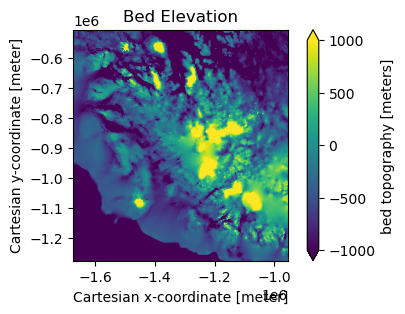

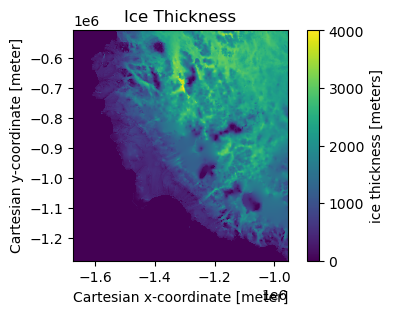

In [19]:
#initial Pots from Bedmachine3

#Plot bed elevation
fig, ax = plt.subplots(figsize=(5, 3))
test_area1["bed"].plot(ax=ax, x="x", y="y", cmap="viridis", add_colorbar=True, vmin = -1000, vmax = 1000)
ax.set_title("Bed Elevation")
ax.set_aspect("equal")
plt.show()

#Plot Ice Thickness
fig, ax = plt.subplots(figsize=(5, 3))
test_area1["thickness"].plot(ax=ax, x="x", y="y", cmap="viridis", add_colorbar=True)
ax.set_title("Ice Thickness")
ax.set_aspect("equal")
plt.show()